# Information vs intensity contrast (referee analysis)

The intensities are renormalised so that $\sum_v I_v = 1$, so the total
photon budget is *fixed*: the contrast $r = I_\mathrm{mid}/I_\mathrm{out}$
only **reallocates** a constant budget between the depth (middle) source and
the two transverse width sources. `target_point_source_idx = 0` is the middle
(depth) source, so $r>1$ brightens the depth source at the expense of the
width pair, and $r<1$ does the opposite.

This is the non-uniform analogue of the uniform-efficiency argument in the
paper (a uniform $\eta$ rescales every channel equally and cancels in the
MS-vs-quantum comparison).

In [1]:
import glob
import re

import matplotlib.pyplot as plt
import numpy as np

from visualize_helpers import latexify

latexify()
FORMAT = "pdf"

In [2]:
%matplotlib inline

## Load data

In [3]:
# Read the contrasts from whatever simulation output is on disk, so this
# notebook works for both the original and the denser log-symmetric sweep.
contrasts = sorted(
    float(re.search(r"qfi_(\d+\.\d+)\.npy", f).group(1))  # type: ignore
    for f in glob.glob("qfi_*.npy")
    if "_inv_" not in f
)

coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

qfis = [np.load(f"qfi_{c:.2f}.npy") for c in contrasts]
qfis_inv = [np.load(f"qfi_inv_{c:.2f}.npy") for c in contrasts]
fis = [np.load(f"fi_ms_{c:.2f}.npy") for c in contrasts]
fis_inv = [np.load(f"fi_ms_inv_{c:.2f}.npy") for c in contrasts]
contrasts

[0.2,
 0.23,
 0.28,
 0.32,
 0.38,
 0.45,
 0.53,
 0.62,
 0.72,
 0.85,
 1.0,
 1.17,
 1.38,
 1.62,
 1.9,
 2.24,
 2.63,
 3.09,
 3.62,
 4.26,
 5.0]

In [4]:
# Per-source weights for V = 3 (sum to 1 by construction), and helpers for
# slicing a single geometry out of the (Nx, Nz, 2, 2) bound arrays.
c_arr = np.array(contrasts)
baseline = contrasts.index(1.0)
I_mid = c_arr / (c_arr + 2)  # middle / depth source weight
I_out = 1.0 / (c_arr + 2)  # each transverse / width source weight

fis_sum = [np.sum(fi, axis=2) for fi in fis]  # sum MS FI over mode channels


def _idx(arr: np.ndarray, val: float) -> int:
    """Grid index nearest to a target coordinate value."""
    return int(np.argmin(np.abs(arr - val)))


def _series(arrays: list[np.ndarray], ix: int, iz: int, a: int, b: int) -> np.ndarray:
    """Bound component (a, b) at a fixed geometry, one value per contrast."""
    return np.array([A[ix, iz, a, b] for A in arrays])


# A clean width signal lives at small depth and vice-versa.
iz_w = _idx(p_range, 0.2)
ix_d = _idx(x_range, 0.3)
width_ix = [_idx(x_range, v) for v in (0.5, 1.0, 2.0, 3.5)]
depth_iz = [_idx(p_range, v) for v in (0.2, 0.5, 1.0, 1.7)]

# Single both-sub-Rayleigh geometry for the asymmetry / transfer figures.
ix_sel, iz_sel = _idx(x_range, 0.5 / np.sqrt(2)), _idx(p_range, 0.5)

# Three representative (delta x, delta z) regimes for the FI/CRB-vs-contrast
# figure, in normalized units (sqrt(k/z_R) delta x and delta z / z_R); the
# Rayleigh scale is ~1, so sub-Rayleigh means < 1. The three pairs differ in
# *both* delta x and delta z so neither the width nor the depth panel has
# coincident curves (curves sharing a delta x overlap in the width panel,
# since H_xx is set by delta x alone).
geoms = [
    (
        "both_subR_tight",
        "both deep sub-Rayleigh",
        _idx(x_range, 0.3 / np.sqrt(2)),
        _idx(p_range, 0.3),
    ),
    (
        "width_subR_depth_mid",
        r"width sub-Rayleigh, depth mid",
        _idx(x_range, 0.53 / np.sqrt(2)),
        _idx(p_range, 0.89),
    ),
    (
        "width_mid_depth_subR",
        r"width mid, depth sub-Rayleigh",
        _idx(x_range, 0.89 / np.sqrt(2)),
        _idx(p_range, 0.53),
    ),
]
Q, MS = "tab:red", "tab:blue"
geom_txt = (
    rf"$\sqrt{{k/z_R}}\,\delta x={np.sqrt(2) * x_range[ix_sel]:.2f}$, "
    rf"$\delta z/z_R={p_range[iz_sel]:.2f}$"
)

## 1. FI and CRB vs contrast at representative geometries

All three geometry regimes on one figure: QFI in shades of red and
mode-sorting FI in shades of blue, with the shade fixing the $(\delta x,
\delta z)$ pair (light to dark). Panels are arranged rows = parameter
(width $\delta x$ top, depth $\delta z$ bottom), columns = quantity (FI
left, CRB right). The regimes are (i) both parameters sub-Rayleigh, (ii)
width sub-Rayleigh with depth near the Rayleigh length, and (iii) the
reverse -- the table columns give $(\sqrt{k/z_R}\,\delta x,\ \delta
z/z_R)$, where $\approx 1$ is the Rayleigh scale. The dashed vertical line
marks equal brightness ($r = 1$).

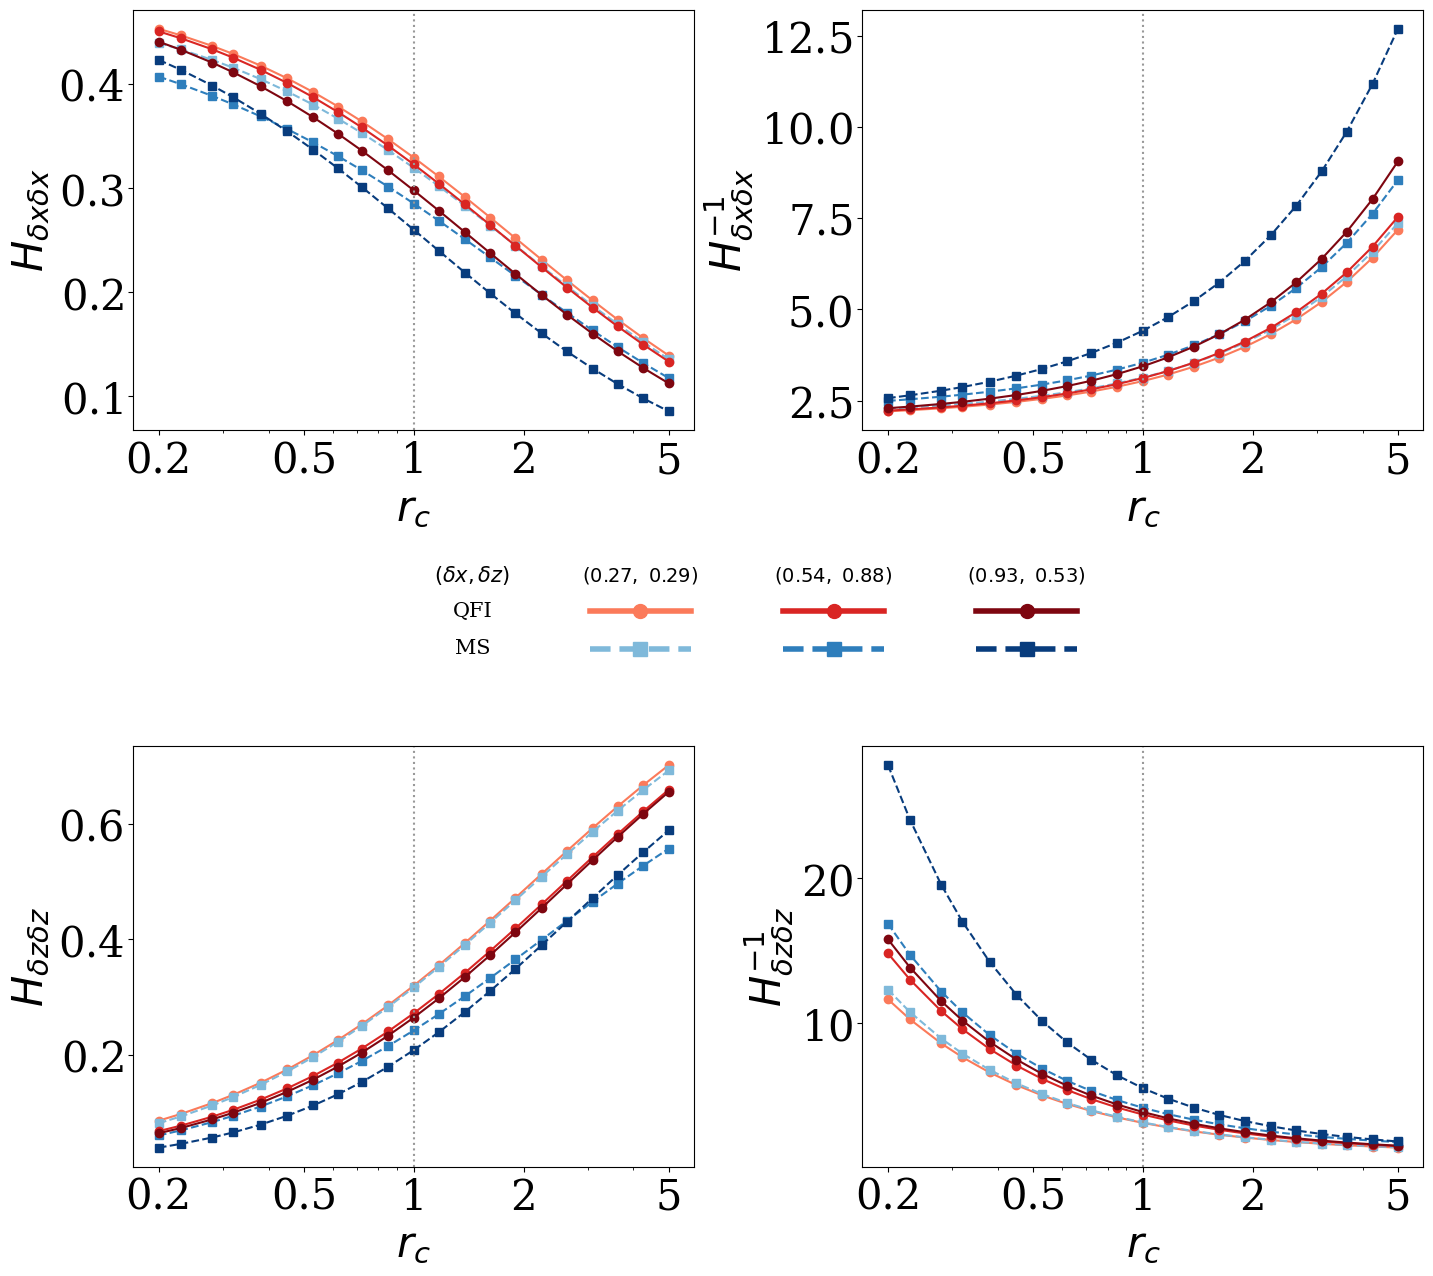

In [5]:
from matplotlib.ticker import FuncFormatter, NullFormatter

# Plain-number x ticks (no 10^x superscripts) and no labelled minor ticks.
_g = FuncFormatter(lambda v, _: f"{v:g}")

# Shade encodes the (delta x, delta z) pair; hue encodes QFI (red) vs MS (blue).
shades_q = plt.cm.Reds(np.linspace(0.45, 0.95, len(geoms)))  # type: ignore
shades_m = plt.cm.Blues(np.linspace(0.45, 0.95, len(geoms)))  # type: ignore

# Panels: rows = parameter (width / depth), columns = quantity (FI / CRB).
panel_spec = [
    (0, 0, qfis, fis_sum, r"$H_{\delta x \delta x}$"),
    (0, 0, qfis_inv, fis_inv, r"$H^{-1}_{\delta x \delta x}$"),
    (1, 1, qfis, fis_sum, r"$H_{\delta z \delta z}$"),
    (1, 1, qfis_inv, fis_inv, r"$H^{-1}_{\delta z \delta z}$"),
]
# Explicit log-axis ticks either side of r_c = 1 (default only labels 10^0).
r_ticks = [0.2, 0.5, 1, 2, 5]
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, (a, b, q_arrs, ms_arrs, ysym) in zip(axes.flat, panel_spec):
    for i, (_tag, _glabel, ix, iz) in enumerate(geoms):
        ax.plot(c_arr, _series(q_arrs, ix, iz, a, b), "o-", color=shades_q[i])
        ax.plot(c_arr, _series(ms_arrs, ix, iz, a, b), "s--", color=shades_m[i])
    ax.axvline(1.0, color="0.6", ls=":", lw=1.5)
    ax.set_xscale("log")
    ax.set_xticks(r_ticks)
    ax.xaxis.set_major_formatter(_g)
    ax.xaxis.set_minor_formatter(NullFormatter())
    # y stays linear with default ticks / formatting.
    ax.set_ylabel(ysym)
    ax.set_xlabel(r"$r_c$")
# Open a central band between the panels to host the legend.
fig.subplots_adjust(
    left=0.11, right=0.97, top=0.96, bottom=0.07, hspace=0.75, wspace=0.30
)

# Table-style legend (borderless): top-left names the tuple, columns are the
# (delta x, delta z) pairs, rows are QFI / MS drawn as thick lines matching the
# curve styles (solid+circle QFI, dashed+square MS) in the per-pair shade.
pair_labels = [
    rf"$({np.sqrt(2) * x_range[ix]:.2f},\ {p_range[iz]:.2f})$" for _, _, ix, iz in geoms
]
lax = fig.add_axes((0.28, 0.455, 0.56, 0.085))
lax.set_xlim(0, 1)
lax.set_ylim(0, 1)
lax.axis("off")
lx = 0.10
cx = [0.30 + i * 0.23 for i in range(len(geoms))]
y_hdr, y_q, y_m = 0.82, 0.50, 0.16
lax.text(lx, y_hdr, r"$(\delta x, \delta z)$", ha="center", va="center", fontsize=15)
lax.text(lx, y_q, "QFI", ha="center", va="center", fontsize=15)
lax.text(lx, y_m, "MS", ha="center", va="center", fontsize=15)
for i, x in enumerate(cx):
    lax.text(x, y_hdr, pair_labels[i], ha="center", va="center", fontsize=14)
    lax.plot(
        [x - 0.06, x, x + 0.06],
        [y_q] * 3,
        "-",
        color=shades_q[i],
        lw=4,
        marker="o",
        markersize=10,
        markevery=[1],
        clip_on=False,
    )
    lax.plot(
        [x - 0.06, x, x + 0.06],
        [y_m] * 3,
        "--",
        color=shades_m[i],
        lw=4,
        marker="s",
        markersize=10,
        markevery=[1],
        clip_on=False,
    )

fig.savefig(f"fi_crb_vs_contrast.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## 2. Is it only photon reallocation? (normalised collapse)

Each curve is the bound at one geometry, divided by its equal-brightness
value, vs contrast. The dashed black line is the *pure-reallocation*
prediction -- the responsible source's weight, normalised the same way
($I_\mathrm{out}$ for width, $I_\mathrm{mid}$ for depth). Curves landing on
the dashed line are explained entirely by the photon budget moving between
sources; departures are the genuine structural (overlap) effect.

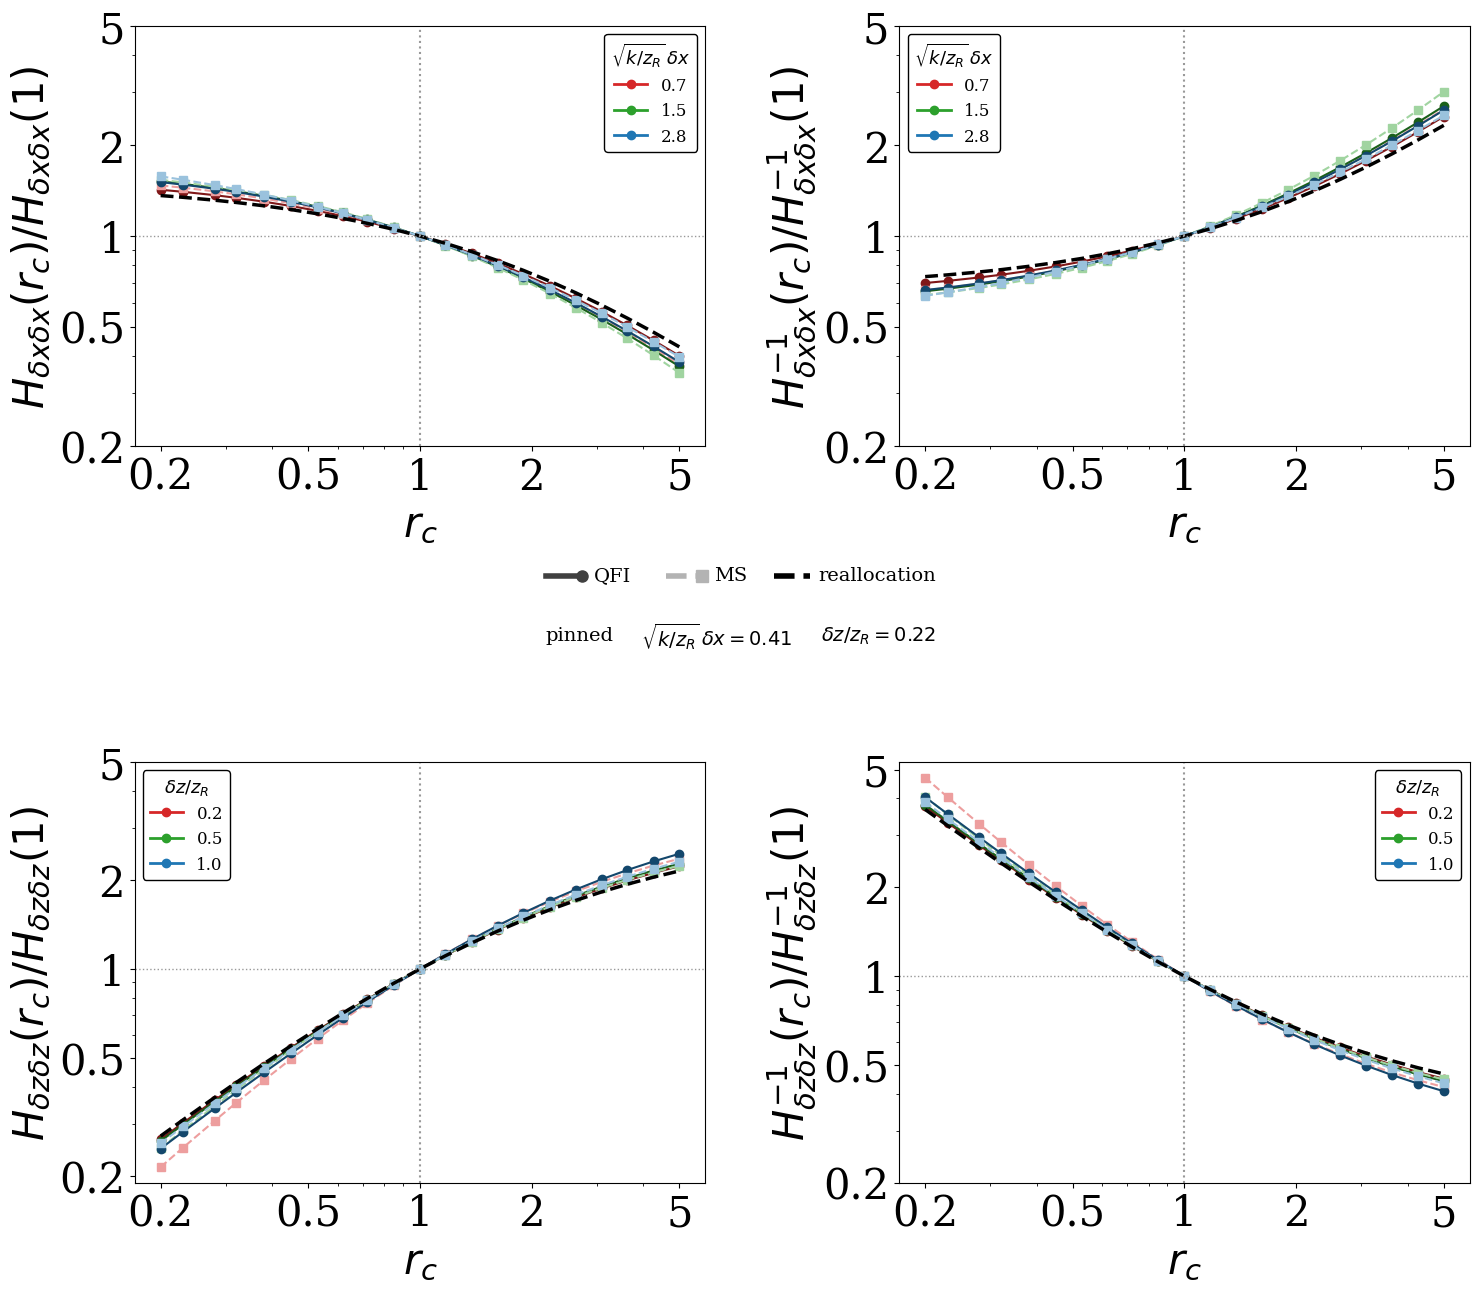

In [6]:
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter

# Plain-number tick labels (no 10^x superscripts) and no labelled minor ticks.
_g = FuncFormatter(lambda v, _: f"{v:g}")

# Three geometries per parameter; ALL curves use red/green/blue, with QFI = the
# darker shade and MS = the lighter shade of the same colour. Width curves vary
# delta x at fixed small depth (iz_w); depth curves vary delta z at fixed small
# width (ix_d).
width_ix3 = [_idx(x_range, v) for v in (0.5, 1.0, 2.0)]
depth_iz3 = [_idx(p_range, v) for v in (0.2, 0.5, 1.0)]
base_cols = ["tab:red", "tab:green", "tab:blue"]


def _darker(c, f: float = 0.6) -> tuple:  # noqa: ANN001
    return tuple(f * np.array(mcolors.to_rgb(c)))


def _lighter(c, f: float = 0.55) -> tuple:  # noqa: ANN001
    rgb = np.array(mcolors.to_rgb(c))
    return tuple(rgb + (1.0 - rgb) * f)


# Pure-reallocation prediction: the responsible source's weight, normalised at
# r = 1. It is estimator-independent (photon budget, not QFI vs MS), so there is
# ONE dashed line per panel; FI tracks the weight ratio, the CRB its reciprocal.
w_pred = I_out / I_out[baseline]
d_pred = I_mid / I_mid[baseline]
r_ticks = [0.2, 0.5, 1, 2, 5]
width_lbls = [f"{np.sqrt(2) * x_range[ix]:.1f}" for ix in width_ix3]
depth_lbls = [f"{p_range[iz]:.1f}" for iz in depth_iz3]

# Layout matches figure 1: rows = parameter (width top, depth bottom), columns =
# quantity (FI left, CRB right). The value legend is duplicated in both panels
# of each row.
panel_spec = [
    (
        0,
        width_ix3,
        iz_w,
        r"\delta x \delta x",
        w_pred,
        True,
        width_lbls,
        r"$\sqrt{k/z_R}\,\delta x$",
    ),
    (
        1,
        depth_iz3,
        ix_d,
        r"\delta z \delta z",
        d_pred,
        False,
        depth_lbls,
        r"$\delta z/z_R$",
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for row, (ab, idxs, fix, sym, pred, is_width, vlbls, vtitle) in enumerate(panel_spec):
    cols = [
        (qfis, fis_sum, pred, rf"$H_{{{sym}}}(r_c)/H_{{{sym}}}(1)$"),
        (
            qfis_inv,
            fis_inv,
            1.0 / pred,
            rf"$H^{{-1}}_{{{sym}}}(r_c)/H^{{-1}}_{{{sym}}}(1)$",
        ),
    ]
    for col, (q_arr, m_arr, pred_c, ysym) in enumerate(cols):
        ax = axes[row, col]
        for i, j in enumerate(idxs):
            ix, iz = (j, fix) if is_width else (fix, j)
            yq = _series(q_arr, ix, iz, ab, ab)
            ym = _series(m_arr, ix, iz, ab, ab)
            ax.plot(c_arr, yq / yq[baseline], "o-", color=_darker(base_cols[i]))
            ax.plot(c_arr, ym / ym[baseline], "s--", color=_lighter(base_cols[i]))
        ax.plot(c_arr, pred_c, "k--", lw=2.5)
        ax.axvline(1.0, color="0.6", ls=":", lw=1.5)
        ax.axhline(1.0, color="0.6", ls=":", lw=1.0)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xticks(r_ticks)
        ax.set_yticks(r_ticks)
        ax.xaxis.set_major_formatter(_g)
        ax.yaxis.set_major_formatter(_g)
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_ylabel(ysym)
        ax.set_xlabel(r"$r_c$")
        # In-panel value legend (colour -> swept value), duplicated per row.
        vh = [
            Line2D([0], [0], color=base_cols[i], ls="-", marker="o", lw=2)
            for i in range(len(idxs))
        ]
        leg = ax.legend(
            vh,
            vlbls,
            title=vtitle,
            frameon=True,
            fontsize=12,
            title_fontsize=13,
            loc="best",
        )
        leg.get_frame().set_facecolor("white")
        leg.get_frame().set_edgecolor("black")
        leg.get_frame().set_alpha(1.0)

# Wider gap between the left/right columns; band between rows for the centre legend.
fig.subplots_adjust(
    left=0.08, right=0.97, top=0.95, bottom=0.06, hspace=0.75, wspace=0.34
)

# Centre two-row legend, horizontally centred in the figure. Positions tuned by
# rendering: QFI / MS / reallocation evenly spread (MS central, the dashed line
# right against its text); row 2 = pinned, then dx centred between pinned and dz.
lax = fig.add_axes((0.33, 0.45, 0.4, 0.11))
lax.set_xlim(0, 1)
lax.set_ylim(0, 1)
lax.axis("off")

y1, y2, L, xr = 0.70, 0.28, 0.06, 0.71
# Row 1.
lax.plot(
    [0.06, 0.06 + L],
    [y1, y1],
    "-",
    color="0.25",
    lw=4,
    marker="o",
    markevery=[1],
    markersize=8,
    clip_on=False,
)
lax.text(0.06 + L + 0.02, y1, "QFI", ha="left", va="center", fontsize=14)
lax.plot(
    [0.26, 0.26 + L],
    [y1, y1],
    "--",
    color="0.70",
    lw=4,
    marker="s",
    markevery=[1],
    markersize=8,
    clip_on=False,
)
lax.text(0.26 + L + 0.02, y1, "MS", ha="left", va="center", fontsize=14)
lax.plot([0.44, 0.44 + L], [y1, y1], "--", color="k", lw=4, clip_on=False)
lax.text(xr, y1, "reallocation", ha="right", va="center", fontsize=14)
# Row 2.
lax.text(0.06, y2, "pinned", ha="left", va="center", fontsize=14)
lax.text(
    0.345,
    y2,
    rf"$\sqrt{{k/z_R}}\,\delta x={np.sqrt(2) * x_range[ix_d]:.2f}$",
    ha="center",
    va="center",
    fontsize=14,
)
lax.text(
    xr, y2, rf"$\delta z/z_R={p_range[iz_w]:.2f}$", ha="right", va="center", fontsize=14
)

fig.savefig(
    f"contrast_reallocation_collapse.{FORMAT}", format=FORMAT, bbox_inches="tight"
)
plt.show()

## 3. Mode-sorting efficiency vs contrast

The ratio $\eta = H_\mathrm{MS}/\mathcal{Q}$ of mode-sorting FI to the
quantum bound. If $\eta$ is flat in $r$, the MS-vs-quantum comparison is
robust to brightness imbalance -- imbalance moves information between the two
parameters but does not change how well mode sorting captures it.

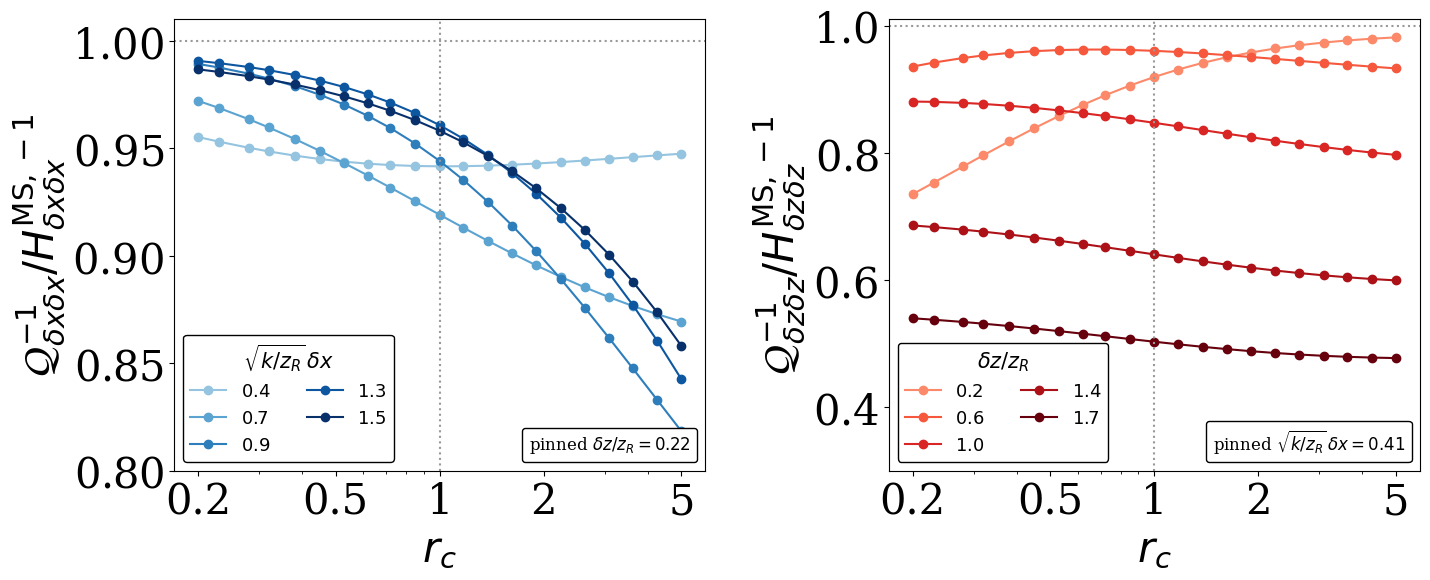

In [7]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter

# Plain-number tick labels (no 10^x superscripts) and no labelled minor ticks.
_g = FuncFormatter(lambda v, _: f"{v:g}")

# Mode-sorting CRB efficiency = (quantum CRB) / (MS CRB) = Q^-1 / H^-1, one curve
# per geometry. We use the CRB (full matrix inverse) rather than the marginal FI
# ratio because it is correlation-aware (the FI ratio drops the delta x - delta z
# correlation). The ratio is <= 1; flat-and-high in r_c is the point: MS stays
# near-optimal under brightness imbalance. Separations are sub-Rayleigh (up to
# ~1.5 / 1.7), shaded light -> dark; width = Blues, depth = Reds. NB sub-Rayleigh
# width efficiency is ~delta x-independent so those curves nearly coincide
# (uniformly near-optimal); depth spreads out. The pinned orthogonal coordinate
# is a separate legend in the bottom-right corner.
width_ix5 = [_idx(x_range, v) for v in (0.3, 0.5, 0.7, 0.9, 1.05)]
depth_iz5 = [_idx(p_range, v) for v in (0.2, 0.6, 1.0, 1.4, 1.7)]
width_cols = plt.cm.Blues(np.linspace(0.4, 1.0, len(width_ix5)))  # type: ignore
depth_cols = plt.cm.Reds(np.linspace(0.4, 1.0, len(depth_iz5)))  # type: ignore
r_ticks = [0.2, 0.5, 1, 2, 5]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
dx_l = r"$\mathcal{Q}^{-1}_{\delta x \delta x}/H^{\mathrm{MS},-1}_{\delta x \delta x}$"
dz_l = r"$\mathcal{Q}^{-1}_{\delta z \delta z}/H^{\mathrm{MS},-1}_{\delta z \delta z}$"
panels = [
    (
        axes[0],
        0,
        width_ix5,
        iz_w,
        width_cols,
        True,
        (0.8, 1.01),
        dx_l,
        r"$\sqrt{k/z_R}\,\delta x$",
        [rf"${np.sqrt(2) * x_range[i]:.1f}$" for i in width_ix5],
        rf"pinned $\delta z/z_R={p_range[iz_w]:.2f}$",
    ),
    (
        axes[1],
        1,
        depth_iz5,
        ix_d,
        depth_cols,
        False,
        (0.3, 1.01),
        dz_l,
        r"$\delta z/z_R$",
        [rf"${p_range[i]:.1f}$" for i in depth_iz5],
        rf"pinned $\sqrt{{k/z_R}}\,\delta x={np.sqrt(2) * x_range[ix_d]:.2f}$",
    ),
]
for (
    ax,
    ab,
    idxs,
    fix,
    pal,
    is_width,
    ylim,
    ysym,
    leg_title,
    leg_lbls,
    pin_lbl,
) in panels:
    for i, j in enumerate(idxs):
        ix, iz = (j, fix) if is_width else (fix, j)
        eta = _series(qfis_inv, ix, iz, ab, ab) / _series(fis_inv, ix, iz, ab, ab)
        ax.plot(c_arr, eta, "o-", color=pal[i], label=leg_lbls[i])
    ax.axhline(1.0, color="0.6", ls=":", lw=1.5)  # quantum-optimal
    ax.axvline(1.0, color="0.6", ls=":", lw=1.5)  # equal brightness
    ax.set_xscale("log")
    ax.set_xticks(r_ticks)
    ax.xaxis.set_major_formatter(_g)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_ylim(*ylim)
    ax.set_ylabel(ysym)
    ax.set_xlabel(r"$r_c$")
    # Legend 1: colour -> swept value, bottom-left, solid white box.
    leg = ax.legend(
        title=leg_title,
        frameon=True,
        fontsize=13,
        title_fontsize=15,
        loc="lower left",
        ncol=2,
    )
    leg.get_frame().set_facecolor("white")
    leg.get_frame().set_edgecolor("black")
    leg.get_frame().set_alpha(1.0)
    ax.add_artist(leg)
    # Legend 2: the pinned orthogonal coordinate, bottom-right corner.
    pin_leg = ax.legend(
        [Line2D([], [], ls="none", marker="none")],
        [pin_lbl],
        loc="lower right",
        frameon=True,
        fontsize=12,
        handlelength=0,
        handletextpad=0,
    )
    pin_leg.get_frame().set_facecolor("white")
    pin_leg.get_frame().set_edgecolor("black")
    pin_leg.get_frame().set_alpha(1.0)

fig.tight_layout()
fig.savefig(f"ms_efficiency_vs_contrast.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## 4. Footnote: the contrast asymmetry is the weight map, not physics

The width and depth QFI move in opposite directions with $r$, and the
response is *asymmetric* about $r = 1$. This asymmetry is not physics: it is
the nonlinearity of the source-weight map $I(r) = r/(r+2)$. Plotted against
the responsible source's weight rather than against $r$, the QFI is -- to
leading order -- linear, and the asymmetry disappears. This is the same
statement as the pure-reallocation collapse in §2 (where the dashed line
*is* that weight ratio); the opposite-direction movement is shown explicitly
as a parametric exchange in §5.

## 4. Information transfer: axial ↔ planar brightness

Parametric trade-off at the fixed geometry: each point is one contrast, the
axes are the width ($\delta x$) and depth ($\delta z$) information. As the
contrast switches brightness from the planar (width) sources toward the axial
(depth) source, the curve moves up-and-left -- depth information is *gained*
exactly as width information is *lost*, and vice-versa. The star marks equal
brightness ($r = 1$); QFI and MS trace the same exchange (the MS loop sits
just inside the quantum one).

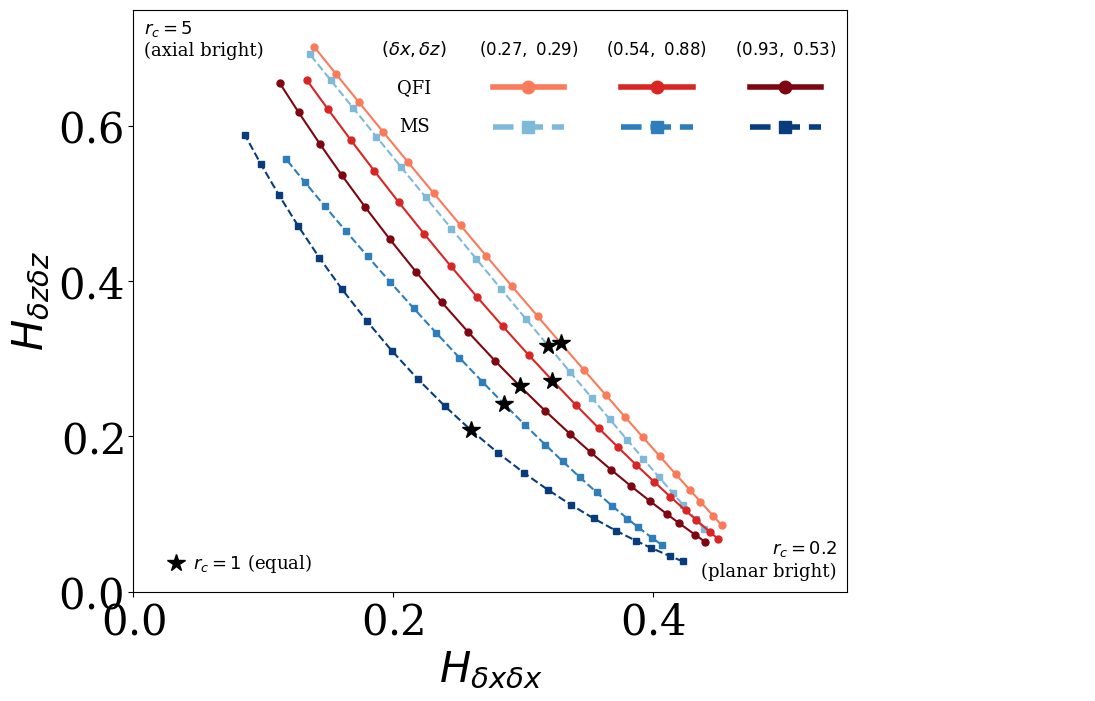

In [8]:
# Information exchange at several geometries (figure-1 convention): each loop is
# the width/depth QFI (red shades) or MS (blue shades) traced over contrast, the
# shade fixing the (delta x, delta z) pair (light -> dark). The loops fan out --
# QFI upper-right, MS lower-left -- and a black star marks equal brightness on
# each. Contrast runs along every loop from r_c = 5 (axial bright, top-left) to
# r_c = 0.2 (planar bright, bottom-right). The r_c right axis of the
# single-geometry version is dropped: height -> r_c can only be calibrated to one
# loop, so it would be dishonest across several.
shades_q = plt.cm.Reds(np.linspace(0.45, 0.95, len(geoms)))  # type: ignore
shades_m = plt.cm.Blues(np.linspace(0.45, 0.95, len(geoms)))  # type: ignore
pair_labels = [
    rf"$({np.sqrt(2) * x_range[ix]:.2f},\ {p_range[iz]:.2f})$" for _, _, ix, iz in geoms
]

fig, ax = plt.subplots(figsize=(8.5, 8.2))
fig.subplots_adjust(left=0.12, right=0.96, bottom=0.09, top=0.80)
for i, (_tag, _lbl, ix, iz) in enumerate(geoms):
    wq = _series(qfis, ix, iz, 0, 0)
    dq = _series(qfis, ix, iz, 1, 1)
    wm = _series(fis_sum, ix, iz, 0, 0)
    dm = _series(fis_sum, ix, iz, 1, 1)
    ax.plot(wq, dq, "o-", color=shades_q[i], ms=5)
    ax.plot(wm, dm, "s--", color=shades_m[i], ms=5)
    ax.plot(wq[baseline], dq[baseline], "*", color="k", ms=13, zorder=5)
    ax.plot(wm[baseline], dm[baseline], "*", color="k", ms=13, zorder=5)
ax.set_xlabel(r"$H_{\delta x \delta x}$")
ax.set_ylabel(r"$H_{\delta z \delta z}$")

ax.set_xlim(0, 0.55)
ax.set_ylim(0, 0.75)
ax.text(
    0.015,
    0.985,
    "$r_c = 5$\n(axial bright)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=13,
)
ax.text(
    0.985,
    0.02,
    "$r_c = 0.2$\n(planar bright)",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13,
)

ax.plot(
    0.06,
    0.05,
    "*",
    color="k",
    ms=13,
    transform=ax.transAxes,
    clip_on=False,
)
ax.text(
    0.25,
    0.03,
    "$r_c = 1$ (equal)",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13,
)

# Primary legend: horizontal figure-1 table in a top banner (loop-free, full
# width); secondary entry on the right gives the equal-brightness star.
lax = fig.add_axes((0.4, 0.63, 0.84, 0.15))
lax.set_xlim(0, 1)
lax.set_ylim(0, 1)
lax.axis("off")
lx = 0.06
cx = [0.22, 0.40, 0.58]
y_hdr, y_q, y_m = 0.82, 0.50, 0.18
lax.text(lx, y_hdr, r"$(\delta x, \delta z)$", ha="center", va="center", fontsize=13)
lax.text(lx, y_q, "QFI", ha="center", va="center", fontsize=13)
lax.text(lx, y_m, "MS", ha="center", va="center", fontsize=13)
for i, x in enumerate(cx):
    lax.text(x, y_hdr, pair_labels[i], ha="center", va="center", fontsize=12)
    lax.plot(
        [x - 0.05, x, x + 0.05],
        [y_q] * 3,
        "-",
        color=shades_q[i],
        lw=4,
        marker="o",
        markersize=9,
        markevery=[1],
        clip_on=False,
    )
    lax.plot(
        [x - 0.05, x, x + 0.05],
        [y_m] * 3,
        "--",
        color=shades_m[i],
        lw=4,
        marker="s",
        markersize=9,
        markevery=[1],
        clip_on=False,
    )

fig.savefig(
    f"contrast_information_transfer.{FORMAT}", format=FORMAT, bbox_inches="tight"
)
plt.show()